# Edge Betweenness Centrality Jaccard Index on Binary Networks (GCC Adaptive Thresholding)

This notebook implements an identical workflow to `weighted/correlationEdgeBetweennessJaccard.ipynb`, but converts the continuous segment-wise Pearson correlation networks into **binary adjacency matrices** using **GCC Adaptive Thresholding** before computing unweighted edge betweenness centrality and evaluating inter-subject Jaccard similarity.

### Thresholding Strategy: GCC Adaptive Binarization
For each segment matrix, we start at an initial threshold of `1.0` and step down by `0.05` until the **Giant Connected Component (GCC)** encompasses 100% of the nodes (`gcc_ratio == 1.0`). At that exact threshold, edges $\ge$ threshold become `1.0` and edges $<$ threshold become `0.0`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

# Robust data directory resolution (handling execution both inside root and inside 'binary/' folder)
abs_segment_base = Path('../correlation_matrices_segment_wise_absolute')
if not abs_segment_base.exists():
    abs_segment_base = Path('correlation_matrices_segment_wise_absolute')
    
matrix_files = list(abs_segment_base.rglob('*.csv'))
if matrix_files:
    sample = pd.read_csv(matrix_files[0], index_col=0)
    print(f"Found {len(matrix_files)} matrix files. Sample shape: {sample.shape}")

# 1. GCC-Adaptive Binary Network Helper
def gcc_ratio(adj):
    G = nx.from_numpy_array(adj)
    if G.number_of_nodes() == 0:
        return 0.0
    comps = list(nx.connected_components(G))
    return max(len(c) for c in comps) / G.number_of_nodes()

def build_binary_network(df, step=0.05):
    abs_corr = np.abs(df.values)
    np.fill_diagonal(abs_corr, 0)

    thr = 1.0
    while thr >= 0.0:
        adj = (abs_corr >= thr).astype(float)
        np.fill_diagonal(adj, 0)
        if gcc_ratio(adj) == 1.0:
            return pd.DataFrame(adj, index=df.index, columns=df.columns), round(thr, 10)
        thr -= step
    # Fallback to fully connected without self loops if needed
    fallback = np.ones_like(abs_corr) - np.eye(df.shape[0])
    return pd.DataFrame(fallback, index=df.index, columns=df.columns), 0.0

# Test binarization on the sample matrix
binary_sample, used_thr = build_binary_network(sample)
print(f"Sample matrix binarized successfully at threshold: {used_thr}")

Found 2632 matrix files. Sample shape: (19, 19)
Sample matrix binarized successfully at threshold: 0.45


## Filter Subjects and Calculate Binary Edge Betweenness Centrality

We filter the exact 20 study subjects and process the first 12 segments for session 1 (`ses-1`). Each individual segment matrix is dynamically converted into an unweighted binary graph using GCC adaptive thresholding, and we calculate standard shortest-path **edge betweenness centrality** (`nx.edge_betweenness_centrality(G)`) for each segment.

In [2]:
# Filter subjects
subject_ids = [64, 65, 69, 70, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 89, 90, 94, 96, 103]
formatted_subjects = [f"sub-NORB{sid:05d}" for sid in subject_ids]

n_segments = 12
subject_segment_eb = {}
subject_edge_betweenness = {}
threshold_tracker = []

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        print(f"Warning: directory not found for {subj}")
        continue
        
    csv_files = sorted(subj_dir.glob('*.csv'))
    if len(csv_files) < n_segments:
        print(f"Warning: {subj} has less than {n_segments} segments")
        
    seg_eb_list = []
    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        bin_df, thr = build_binary_network(df)
        threshold_tracker.append(thr)
        
        # Construct graph directly from binarized adjacency matrix
        G = nx.from_pandas_adjacency(bin_df)
        
        # Calculate unweighted edge betweenness centrality for binary network
        eb = nx.edge_betweenness_centrality(G)
        seg_eb_list.append(eb)
        
    if seg_eb_list:
        subject_segment_eb[subj] = seg_eb_list
        # Average edge betweenness across the 12 segments for overall subject visualization
        all_edges = list(seg_eb_list[0].keys())
        avg_eb = {}
        for u, v in all_edges:
            vals = [s.get((u, v), s.get((v, u), 0.0)) for s in seg_eb_list]
            avg_eb[(u, v)] = np.mean(vals)
        subject_edge_betweenness[subj] = avg_eb
        
print(f"Processed edge betweenness across {n_segments} segments for {len(subject_edge_betweenness)} subjects.")
print(f"Adaptive GCC Threshold Stats --> Min: {min(threshold_tracker):.2f}, Max: {max(threshold_tracker):.2f}, Mean: {np.mean(threshold_tracker):.2f}")

Processed edge betweenness across 12 segments for 20 subjects.
Adaptive GCC Threshold Stats --> Min: 0.25, Max: 0.90, Mean: 0.52


## Plotting Averaged Binary Edge Betweenness across Subjects (Sorted by Age Descending)

We arrange all 171 electrode connection pairs strictly in canonical anatomical order along the x-axis (`F-F`, `F-C`, ..., `O-O`).

On the y-axis, we list all study subjects sorted in descending order of age (oldest on top, youngest on the bottom).

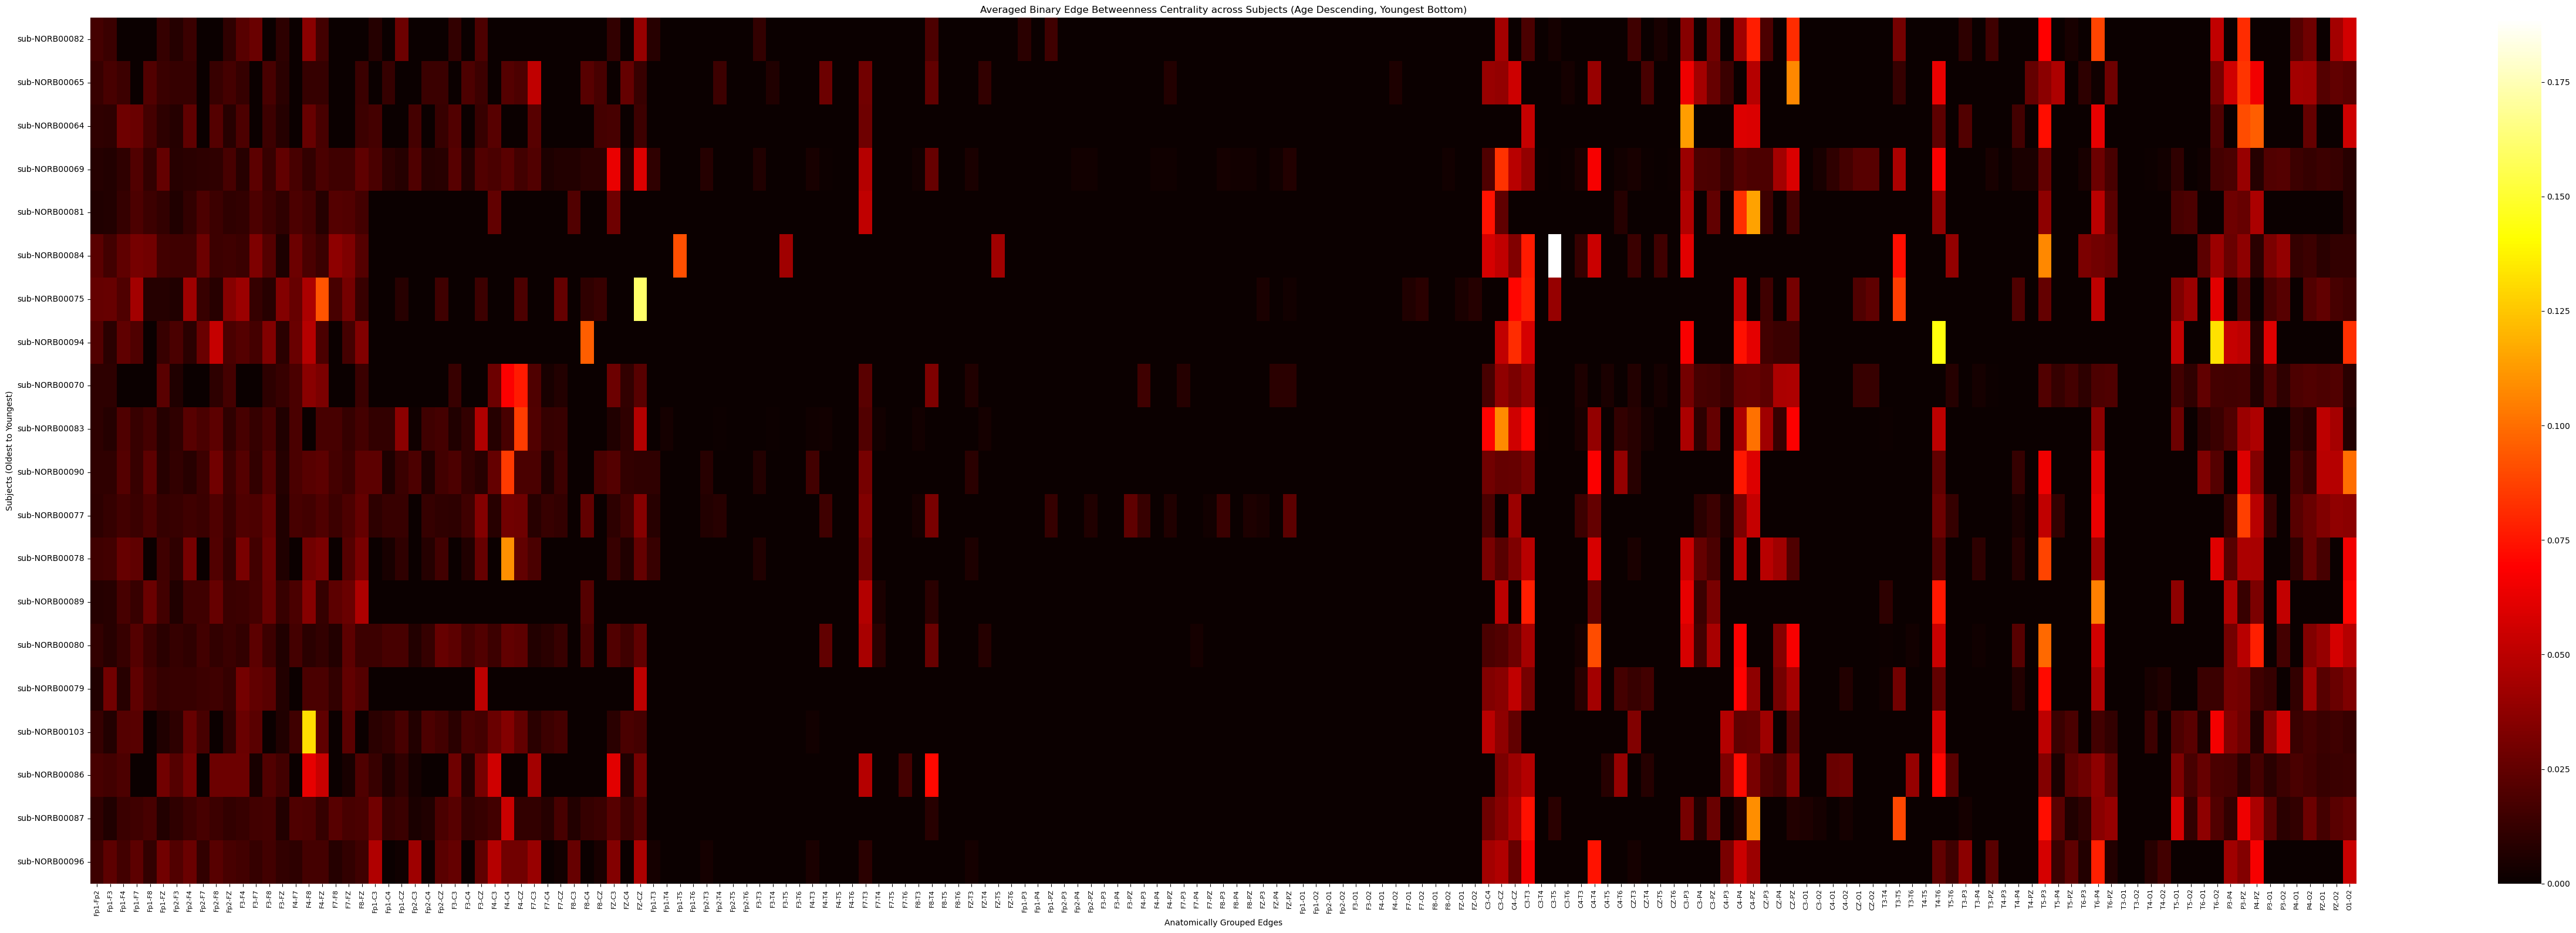

In [3]:
edge_labels = [
    # F-F connections
    'Fp1-Fp2', 'Fp1-F3', 'Fp1-F4', 'Fp1-F7', 'Fp1-F8', 'Fp1-FZ',
    'Fp2-F3', 'Fp2-F4', 'Fp2-F7', 'Fp2-F8', 'Fp2-FZ',
    'F3-F4', 'F3-F7', 'F3-F8', 'F3-FZ',
    'F4-F7', 'F4-F8', 'F4-FZ',
    'F7-F8', 'F7-FZ',
    'F8-FZ',
    # F-C connections
    'Fp1-C3', 'Fp1-C4', 'Fp1-CZ',
    'Fp2-C3', 'Fp2-C4', 'Fp2-CZ',
    'F3-C3', 'F3-C4', 'F3-CZ',
    'F4-C3', 'F4-C4', 'F4-CZ',
    'F7-C3', 'F7-C4', 'F7-CZ',
    'F8-C3', 'F8-C4', 'F8-CZ',
    'FZ-C3', 'FZ-C4', 'FZ-CZ',
    # F-T connections
    'Fp1-T3', 'Fp1-T4', 'Fp1-T5', 'Fp1-T6',
    'Fp2-T3', 'Fp2-T4', 'Fp2-T5', 'Fp2-T6',
    'F3-T3', 'F3-T4', 'F3-T5', 'F3-T6',
    'F4-T3', 'F4-T4', 'F4-T5', 'F4-T6',
    'F7-T3', 'F7-T4', 'F7-T5', 'F7-T6',
    'F8-T3', 'F8-T4', 'F8-T5', 'F8-T6',
    'FZ-T3', 'FZ-T4', 'FZ-T5', 'FZ-T6',
    # F-P connections
    'Fp1-P3', 'Fp1-P4', 'Fp1-PZ',
    'Fp2-P3', 'Fp2-P4', 'Fp2-PZ',
    'F3-P3', 'F3-P4', 'F3-PZ',
    'F4-P3', 'F4-P4', 'F4-PZ',
    'F7-P3', 'F7-P4', 'F7-PZ',
    'F8-P3', 'F8-P4', 'F8-PZ',
    'FZ-P3', 'FZ-P4', 'FZ-PZ',
    # F-O connections
    'Fp1-O1', 'Fp1-O2',
    'Fp2-O1', 'Fp2-O2',
    'F3-O1', 'F3-O2',
    'F4-O1', 'F4-O2',
    'F7-O1', 'F7-O2',
    'F8-O1', 'F8-O2',
    'FZ-O1', 'FZ-O2',
    # C-C connections
    'C3-C4', 'C3-CZ',
    'C4-CZ',
    # C-T connections
    'C3-T3', 'C3-T4', 'C3-T5', 'C3-T6',
    'C4-T3', 'C4-T4', 'C4-T5', 'C4-T6',
    'CZ-T3', 'CZ-T4', 'CZ-T5', 'CZ-T6',
    # C-P connections
    'C3-P3', 'C3-P4', 'C3-PZ',
    'C4-P3', 'C4-P4', 'C4-PZ',
    'CZ-P3', 'CZ-P4', 'CZ-PZ',
    # C-O connections
    'C3-O1', 'C3-O2',
    'C4-O1', 'C4-O2',
    'CZ-O1', 'CZ-O2',
    # T-T connections
    'T3-T4', 'T3-T5', 'T3-T6',
    'T4-T5', 'T4-T6',
    'T5-T6',
    # T-P connections
    'T3-P3', 'T3-P4', 'T3-PZ',
    'T4-P3', 'T4-P4', 'T4-PZ',
    'T5-P3', 'T5-P4', 'T5-PZ',
    'T6-P3', 'T6-P4', 'T6-PZ',
    # T-O connections
    'T3-O1', 'T3-O2',
    'T4-O1', 'T4-O2',
    'T5-O1', 'T5-O2',
    'T6-O1', 'T6-O2',
    # P-P connections
    'P3-P4', 'P3-PZ',
    'P4-PZ',
    # P-O connections
    'P3-O1', 'P3-O2',
    'P4-O1', 'P4-O2',
    'PZ-O1', 'PZ-O2',
    # O-O connections
    'O1-O2'
]

# Load ages and sort subjects descending (oldest top, youngest bottom)
age_csv = Path('../age_acq_time_sorted.csv')
if not age_csv.exists():
    age_csv = Path('age_acq_time_sorted.csv')
    
ages_df = pd.read_csv(age_csv)
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)].copy()
ages_filtered = ages_filtered.sort_values('age_acq_time', ascending=False)

sorted_subject_labels = ages_filtered['label'].tolist()
sorted_subjects = [label.split('_')[0] for label in sorted_subject_labels]

# Prepare data for heatmap
raw_heatmap_data = []
valid_subjects = []

for subj in sorted_subjects:
    if subj in subject_edge_betweenness:
        eb_dict = subject_edge_betweenness[subj]
        row_data = []
        for e in edge_labels:
            u, v = e.split('-')
            val = eb_dict.get((u, v), eb_dict.get((v, u), 0.0))
            row_data.append(val)
        raw_heatmap_data.append(row_data)
        valid_subjects.append(subj)

raw_heatmap_data = np.array(raw_heatmap_data)

# Plot heatmap
plt.figure(figsize=(50, 16))
sns.heatmap(raw_heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=valid_subjects)
plt.title('Averaged Binary Edge Betweenness Centrality across Subjects (Age Descending, Youngest Bottom)')
plt.xlabel('Anatomically Grouped Edges')
plt.ylabel('Subjects (Oldest to Youngest)')
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

## Edge-Wise Binary Betweenness Jaccard Index Calculation

For each of the 190 pairs of subjects (`20C2`), we compute the edge-wise Jaccard similarity of betweenness centrality across corresponding time segments:
1. For each of the 12 segments ($s = 0 \dots 11$), we retrieve the edge betweenness scores $val_A$ and $val_B$ for each canonical electrode connection.
2. We calculate the Jaccard similarity score per edge: $\text{Jaccard}_s = \frac{\min(val_A, val_B)}{\max(val_A, val_B)}$ (if $\max(val_A, val_B) > 0$, else $0$).
3. We **average across these 12 time segments** ($\frac{1}{12}\sum_{s=0}^{11} \text{Jaccard}_s$) to obtain a consistent, stable similarity profile containing exactly 171 edge values per subject pair.

In [4]:
pair_jaccard_all_edges = {}
pair_jaccard_avg = {}

# Iterate over all 20C2 pairs
for subj_A, subj_B in combinations(valid_subjects, 2):
    edge_jaccards = []

    for e in edge_labels:
        u, v = e.split('-')
        segment_jaccards = []

        for s in range(n_segments):
            if s < len(subject_segment_eb[subj_A]) and s < len(subject_segment_eb[subj_B]):
                dict_A = subject_segment_eb[subj_A][s]
                dict_B = subject_segment_eb[subj_B][s]
                
                val_A = dict_A.get((u, v), dict_A.get((v, u), 0.0))
                val_B = dict_B.get((u, v), dict_B.get((v, u), 0.0))

                if max(val_A, val_B) > 0:
                    jaccard_s = min(val_A, val_B) / max(val_A, val_B)
                else:
                    jaccard_s = 0.0
                segment_jaccards.append(jaccard_s)

        # Averaging across the 12 time segments for temporal stability
        avg_s = np.mean(segment_jaccards) if segment_jaccards else 0.0
        edge_jaccards.append(avg_s)

    pair_jaccard_all_edges[(subj_A, subj_B)] = edge_jaccards
    pair_jaccard_avg[(subj_A, subj_B)] = np.mean(edge_jaccards)

print(f"Calculated binary edge betweenness Jaccard indices for all {len(pair_jaccard_all_edges)} subject pairs.")
print(f"Each pair vector contains exactly {len(list(pair_jaccard_all_edges.values())[0])} electrode connections.")

Calculated binary edge betweenness Jaccard indices for all 190 subject pairs.
Each pair vector contains exactly 171 electrode connections.


## Plot Binary Edge Betweenness Centrality Jaccard Index Heatmap (Sorted by Age Difference)

We arrange the subject pairs on the y-axis in descending order of their absolute age difference (largest age difference at the top, smallest at the bottom) and plot the large horizontal heatmap.

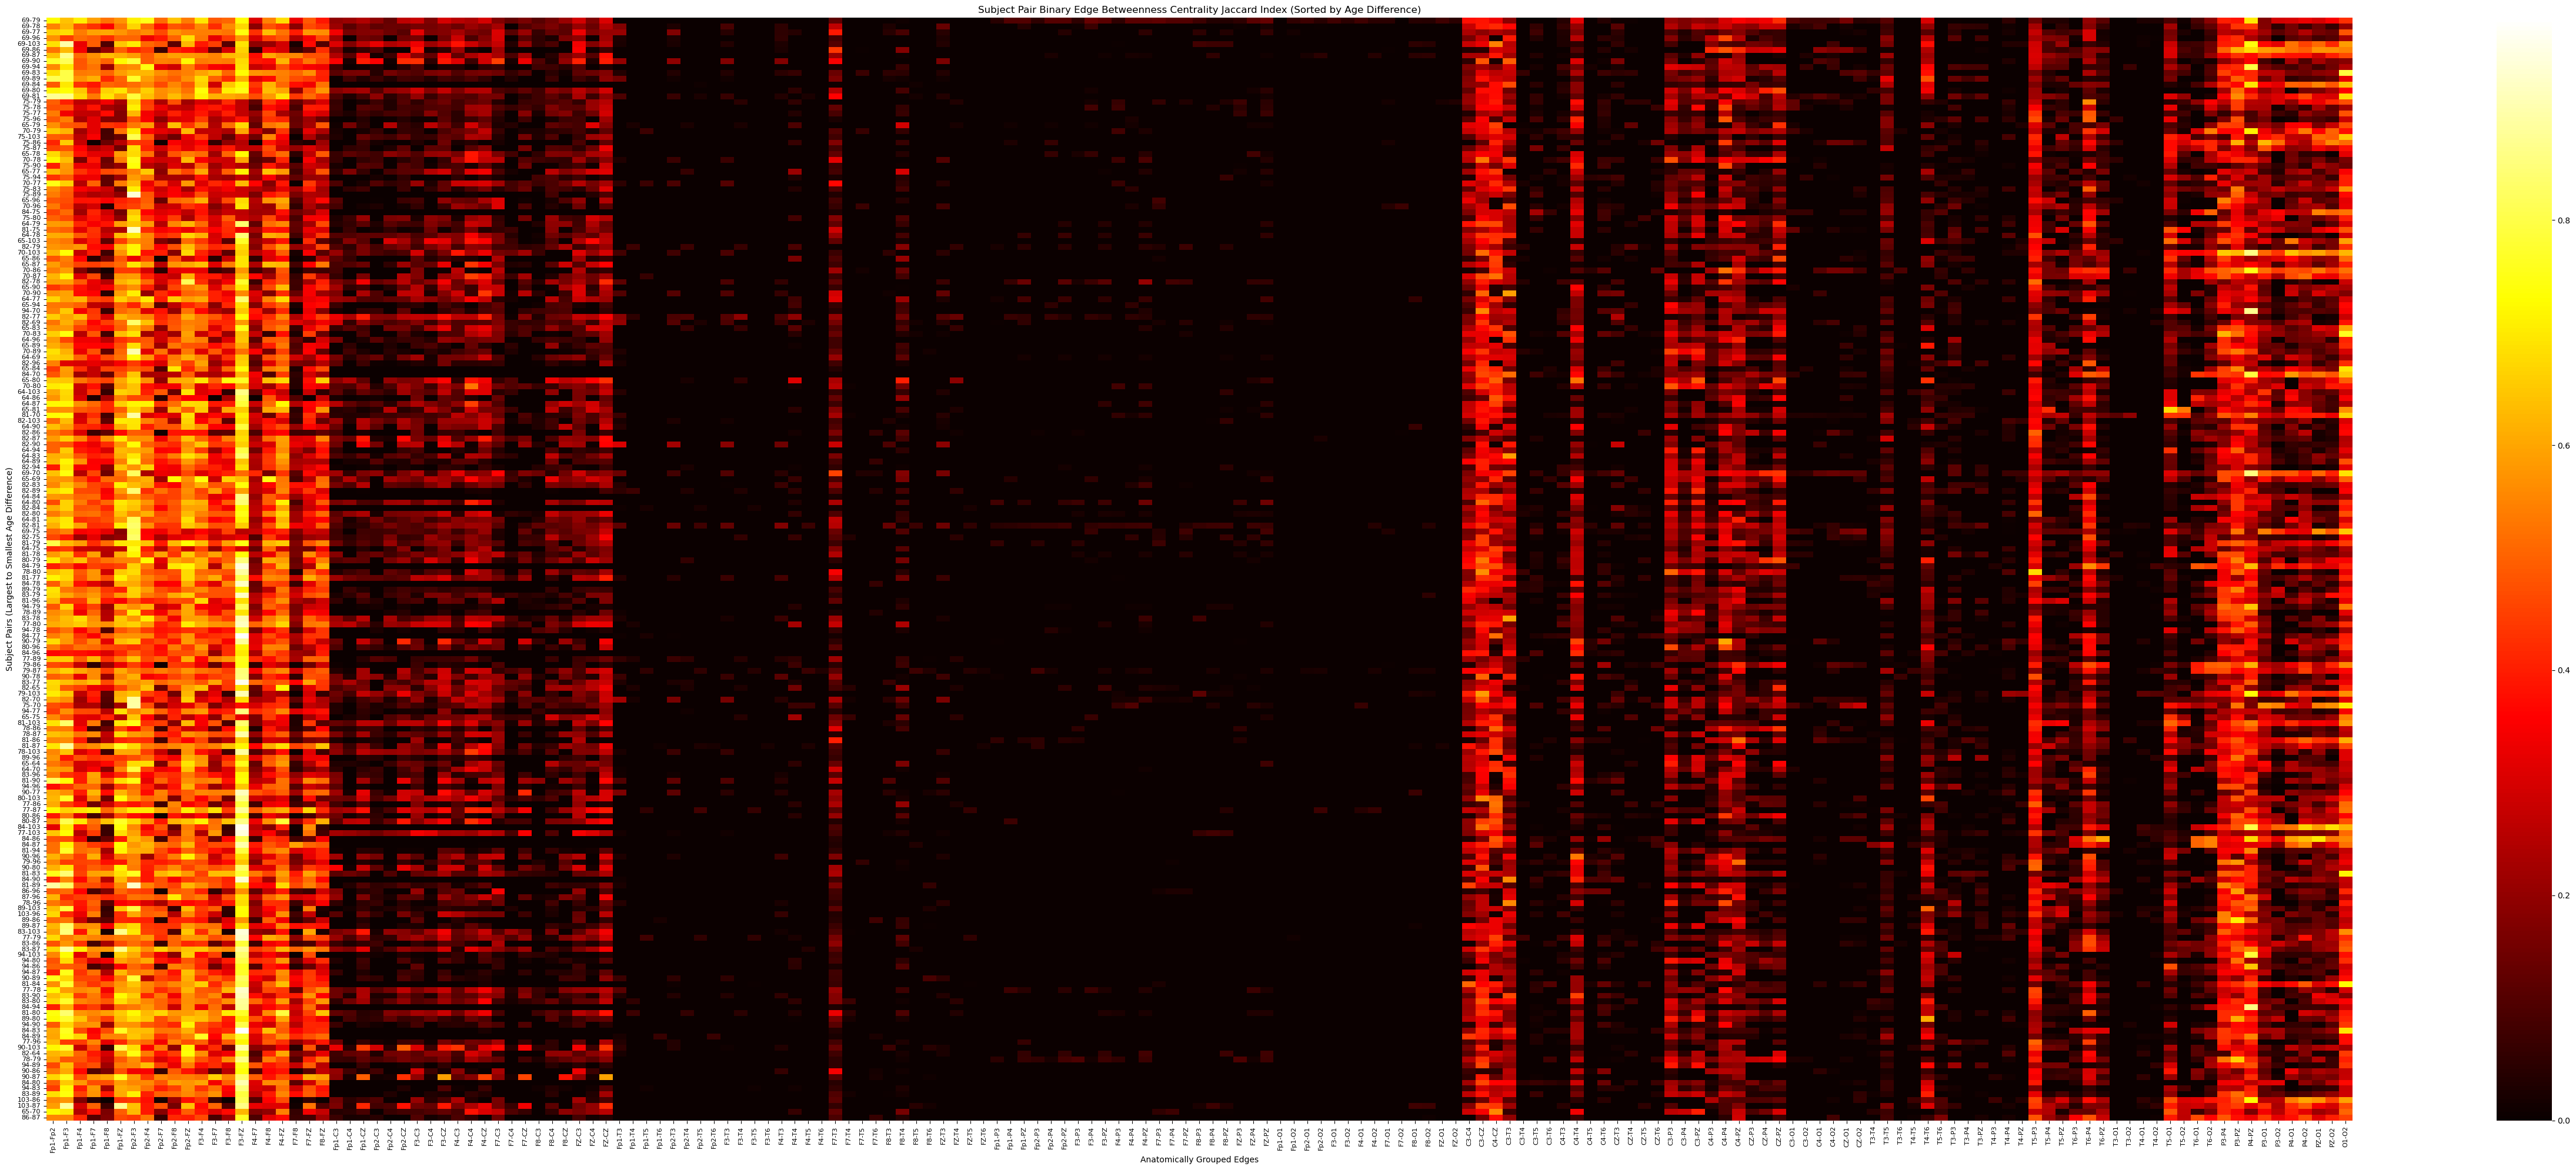

In [5]:
age_dict = {}
for idx, row in ages_df.iterrows():
    subj = row['label'].split('_')[0]
    age_dict[subj] = row['age_acq_time']

pair_age_diff = {}
for pair in pair_jaccard_all_edges.keys():
    subj_A, subj_B = pair
    diff = abs(age_dict[subj_A] - age_dict[subj_B])
    pair_age_diff[pair] = diff

# Sort pairs by age difference descending (largest diff at top, smallest diff at bottom)
sorted_pairs = sorted(pair_age_diff.keys(), key=lambda x: pair_age_diff[x], reverse=True)

heatmap_data = []
yticklabels = []

for pair in sorted_pairs:
    p0 = str(int(pair[0].replace('sub-NORB', '')))
    p1 = str(int(pair[1].replace('sub-NORB', '')))
    yticklabels.append(f"{p0}-{p1}")
    heatmap_data.append(pair_jaccard_all_edges[pair])

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(50, 20))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=yticklabels)
plt.title('Subject Pair Binary Edge Betweenness Centrality Jaccard Index (Sorted by Age Difference)')
plt.xlabel('Anatomically Grouped Edges')
plt.ylabel('Subject Pairs (Largest to Smallest Age Difference)')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## Region-wise Statistical Summary of Binary Edge Betweenness Jaccard Index

This cell calculates and displays a grouped bar plot showing the percentage of Binary Edge Betweenness Jaccard index values exceeding **0.75** and **0.90** for each distinct anatomical brain region connection pair (**F-F**, **F-C**, etc.).

Connection   | Total Values   | % > 0.50   | % > 0.30  
--------------------------------------------------------
F-F          | 3,990          | 38.35      | 77.14     
F-C          | 3,990          | 0.08       | 4.76      
F-T          | 5,320          | 0.00       | 0.30      
F-P          | 3,990          | 0.00       | 0.00      
F-O          | 2,660          | 0.00       | 0.00      
C-C          | 570            | 3.51       | 44.56     
C-T          | 2,280          | 0.35       | 3.73      
C-P          | 1,710          | 0.29       | 10.12     
C-O          | 1,140          | 0.00       | 0.00      
T-T          | 1,140          | 0.18       | 2.72      
T-P          | 2,280          | 0.44       | 8.90      
T-O          | 1,520          | 0.59       | 5.72      
P-P          | 570            | 11.75      | 67.02     
P-O          | 1,140          | 4.30       | 18.68     
O-O          | 190            | 21.58      | 72.11     


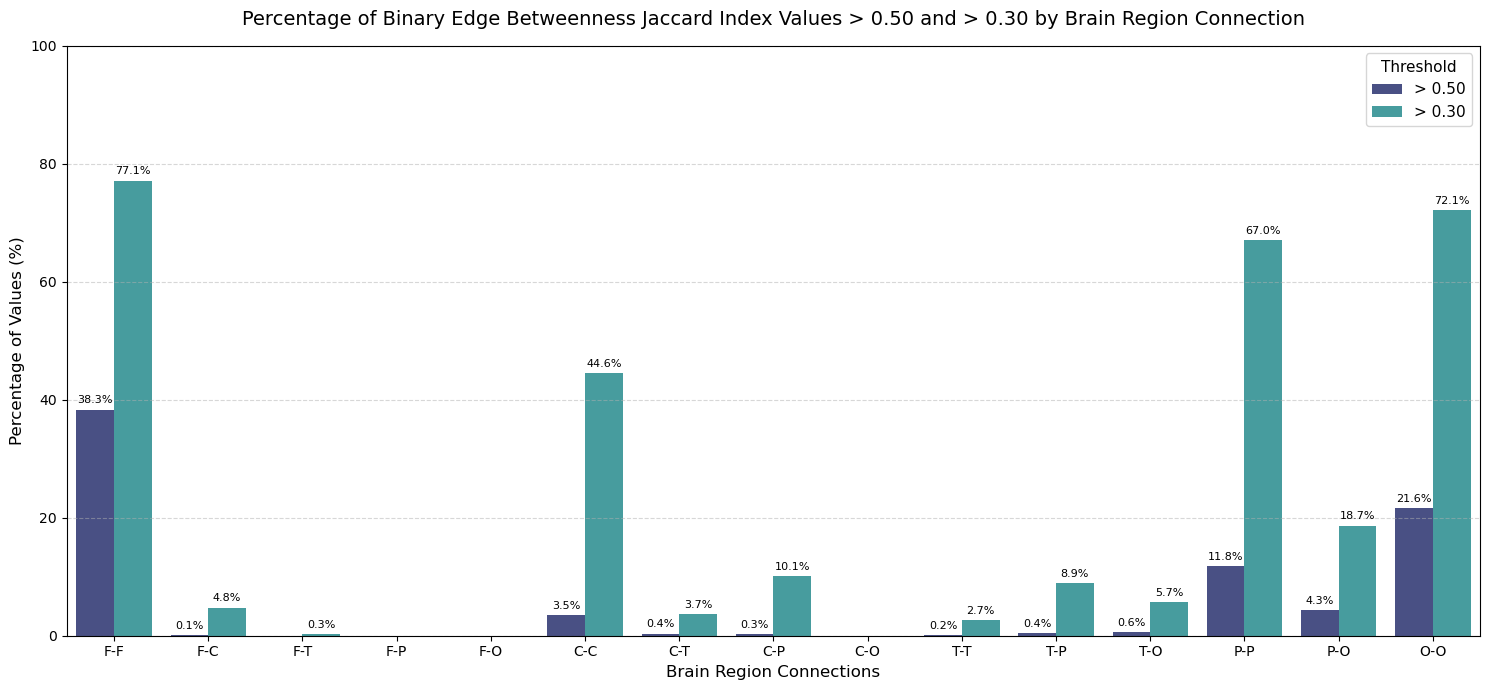

In [6]:
# 1. Define region order and canonical mapping
region_order = {'F': 0, 'C': 1, 'T': 2, 'P': 3, 'O': 4}

def get_region_pair(edge):
    u, v = edge.split('-')
    r1, r2 = u[0], v[0]
    if region_order.get(r1, 99) <= region_order.get(r2, 99):
        return f"{r1}-{r2}"
    else:
        return f"{r2}-{r1}"

# 2. Map every edge in edge_labels to its canonical region pair
region_groups = ['F-F', 'F-C', 'F-T', 'F-P', 'F-O', 
                 'C-C', 'C-T', 'C-P', 'C-O', 
                 'T-T', 'T-P', 'T-O', 
                 'P-P', 'P-O', 
                 'O-O']

region_values = {cat: [] for cat in region_groups}

for idx, edge in enumerate(edge_labels):
    cat = get_region_pair(edge)
    if cat in region_values:
        col_vals = heatmap_data[:, idx]
        region_values[cat].extend(col_vals)

# 3. Calculate percentages > 0.50 and > 0.30
stats_data = []

print(f"{'Connection':<12} | {'Total Values':<14} | {'% > 0.50':<10} | {'% > 0.30':<10}")
print("-" * 56)

for cat in region_groups:
    vals = np.array(region_values[cat])
    total = len(vals)
    if total > 0:
        pct_50 = (np.sum(vals > 0.50) / total) * 100.0
        pct_30 = (np.sum(vals > 0.30) / total) * 100.0
    else:
        pct_50, pct_30 = 0.0, 0.0
        
    val_str = f"{total:,}"
    print(f"{cat:<12} | {val_str:<14} | {pct_50:<10.2f} | {pct_30:<10.2f}")
    
    stats_data.append({'Region Pair': cat, 'Threshold': '> 0.50', 'Percentage': pct_50})
    stats_data.append({'Region Pair': cat, 'Threshold': '> 0.30', 'Percentage': pct_30})

df_stats = pd.DataFrame(stats_data)

# 4. Plot the grouped bar chart
plt.figure(figsize=(15, 7))
ax = sns.barplot(data=df_stats, x='Region Pair', y='Percentage', hue='Threshold', palette='mako')

plt.title('Percentage of Binary Edge Betweenness Jaccard Index Values > 0.50 and > 0.30 by Brain Region Connection', fontsize=14, pad=15)
plt.xlabel('Brain Region Connections', fontsize=12)
plt.ylabel('Percentage of Values (%)', fontsize=12)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels above the bars for clear readability
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 3),
                    textcoords='offset points',
                    fontsize=8, rotation=0)

plt.legend(title='Threshold', fontsize=11, title_fontsize=11)
plt.tight_layout()
plt.show()